In [1]:
import os
import pandas as pd
import numpy as np
from collections import Counter
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer, make_column_transformer
from sklearn.pipeline import make_pipeline
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.pipeline import make_pipeline
from imblearn.pipeline import make_pipeline as imbl_pipe
from imblearn.over_sampling import SMOTE

Load Analytical Base Table

In [2]:
df_data = pd.read_csv(os.path.join("/Users/abhisubrahmanyamkamuju/Desktop/ML_Project/", "analytical_base_table.csv"))
print(f"Dataframe dimensions: {df_data.shape}")
df_data.head()

Dataframe dimensions: (10000, 11)


,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


Separate dataframe into separate object

In [4]:
y_target = df_data.Exited
X_features = df_data.drop(['Exited'], axis=1)
print(X_features.shape, y_target.shape)

(10000, 10) (10000,)


In [5]:
num_cols = X_features.select_dtypes(include='number').columns.tolist()
cat_cols = X_features.select_dtypes(include='object').columns.tolist()

In [7]:
def class_count(arr):
    counter = Counter(arr)
    kv = [list(counter.keys()), list(counter.values())]
    df_counts = pd.DataFrame(np.array(kv).T, columns=['Exited', 'Count'])
    df_counts['Count'] = df_counts['Count'].astype('int64')
    df_counts['%'] = round(df_counts['Count'] / arr.shape[0] * 100, 2)
    return df_counts.sort_values('Count', ascending=False)
class_count(y_target)

,Exited,Count,%
1,0,7963,79.63
0,1,2037,20.37


Create a Train Test Split

In [9]:
random_state = 10

X_train, X_test, y_train, y_test = train_test_split(X_features, y_target, test_size=0.3,
                                                    random_state=random_state,
                                                    stratify=df_data.Exited)

print(len(X_train), len(X_test), len(y_train), len(y_test))
X_train.info()

7000 3000 7000 3000
<class 'pandas.core.frame.DataFrame'>
Index: 7000 entries, 8061 to 4741
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   CreditScore      7000 non-null   int64  
 1   Geography        7000 non-null   object 
 2   Gender           7000 non-null   object 
 3   Age              7000 non-null   int64  
 4   Tenure           7000 non-null   int64  
 5   Balance          7000 non-null   float64
 6   NumOfProducts    7000 non-null   int64  
 7   HasCrCard        7000 non-null   int64  
 8   IsActiveMember   7000 non-null   int64  
 9   EstimatedSalary  7000 non-null   float64
dtypes: float64(2), int64(6), object(2)
memory usage: 601.6+ KB


Pre-processing Pipeline
Scale numerical data and encode categorical data

Construct a pre-processing pipeline from the given transformers: MinMaxScaler and OneHotEncoder

Create lists of indexes from the list of column names

Need to be numeric not string to specify columns name in column transformer

In [10]:
num_indices = [] 
for col in num_cols:
    loc = X_features.columns.get_loc(col)
    num_indices.append(loc)
print(num_indices)  

cat_indices = []
for col in cat_cols:
    loc = X_features.columns.get_loc(col)
    cat_indices.append(loc)
print(cat_indices)  

preprocessor = make_column_transformer(
    (MinMaxScaler(), num_indices),
    (OneHotEncoder(), cat_indices)
)

[0, 3, 4, 5, 6, 7, 8, 9]
[1, 2]


Build Model Pipeline with SMOTE

We are going to use the Pipeline from the imblearn package in place of scikit-learn Pipeline.

It takes care automatically to re-sample when called fit() on the pipeline, and does not re-sample test data (when called transform() or predict()).

In [11]:
from sklearn.svm import SVC 

model_pipe = imbl_pipe(preprocessor,
                       SMOTE(sampling_strategy='auto', random_state=random_state),
                       SVC(random_state=random_state))

param_grid = {'svc__kernel': ['linear', 'rbf', 'poly', 'sigmoid'],
              'svc__C': [0.0005, 0.001, 0.01, 0.1, 0.5],
              'svc__gamma': [5, 1, 0.1, 0.01]}


In [12]:
from sklearn.model_selection import GridSearchCV

grid = GridSearchCV(model_pipe, param_grid, verbose=3, cv=5, n_jobs=4, scoring='accuracy')

X_train = X_train.values
X_test = X_test.values

grid.fit(X_train, y_train)

Fitting 5 folds for each of 80 candidates, totalling 400 fits
[CV 2/5] END svc__C=0.0005, svc__gamma=5, svc__kernel=linear;, score=0.677 total time=   6.0s
[CV 1/5] END svc__C=0.0005, svc__gamma=5, svc__kernel=linear;, score=0.657 total time=   6.0s
[CV 4/5] END svc__C=0.0005, svc__gamma=5, svc__kernel=linear;, score=0.690 total time=   6.0s
[CV 3/5] END svc__C=0.0005, svc__gamma=5, svc__kernel=linear;, score=0.678 total time=   6.4s
[CV 5/5] END svc__C=0.0005, svc__gamma=5, svc__kernel=linear;, score=0.676 total time=   5.7s
[CV 1/5] END svc__C=0.0005, svc__gamma=5, svc__kernel=rbf;, score=0.750 total time=   8.3s
[CV 3/5] END svc__C=0.0005, svc__gamma=5, svc__kernel=rbf;, score=0.562 total time=   7.8s
[CV 2/5] END svc__C=0.0005, svc__gamma=5, svc__kernel=rbf;, score=0.647 total time=   8.0s
[CV 2/5] END svc__C=0.0005, svc__gamma=5, svc__kernel=poly;, score=0.774 total time=   3.6s
[CV 1/5] END svc__C=0.0005, svc__gamma=5, svc__kernel=poly;, score=0.781 total time=   3.6s
[CV 4/5] EN

GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('columntransformer',
                                        ColumnTransformer(transformers=[('minmaxscaler',
                                                                         MinMaxScaler(),
                                                                         [0, 3,
                                                                          4, 5,
                                                                          6, 7,
                                                                          8,
                                                                          9]),
                                                                        ('onehotencoder',
                                                                         OneHotEncoder(),
                                                                         [1,
                                                                          2])])),
                                       ('smote', SMOTE(random_state=10)),
                                       ('svc', SVC(random_state=10))]),
             n_jobs=4,
             param_grid={'svc__C': [0.0005, 0.001, 0.01, 0.1, 0.5],
                         'svc__gamma': [5, 1, 0.1, 0.01],
                         'svc__kernel': ['linear', 'rbf', 'poly', 'sigmoid']},
             scoring='accuracy', verbose=3)

In [13]:
print(grid.best_params_)
print(grid.best_score_)
print(f"Training Data Score: {grid.score(X_train, y_train)}")
print(f"Testing Data Score: {grid.score(X_test, y_test)}")

{'svc__C': 0.5, 'svc__gamma': 5, 'svc__kernel': 'poly'}
0.7862857142857143
Training Data Score: 0.8111428571428572
Testing Data Score: 0.7753333333333333


[[1871  518]
 [ 156  455]]
[[0.78 0.22]
 [0.26 0.74]]


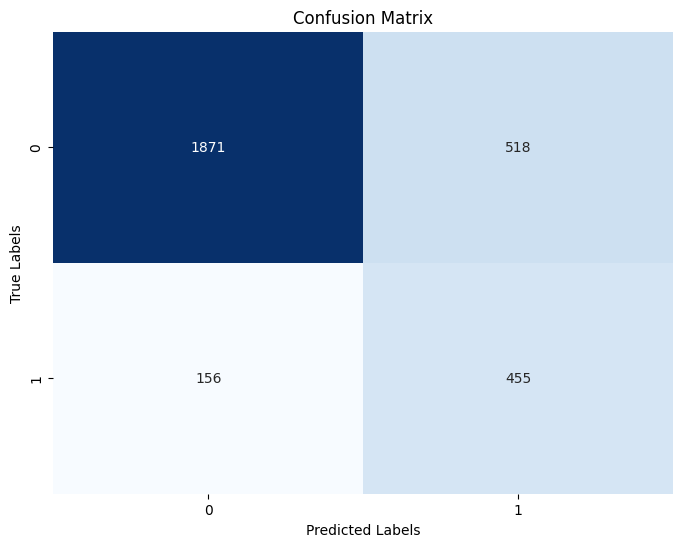

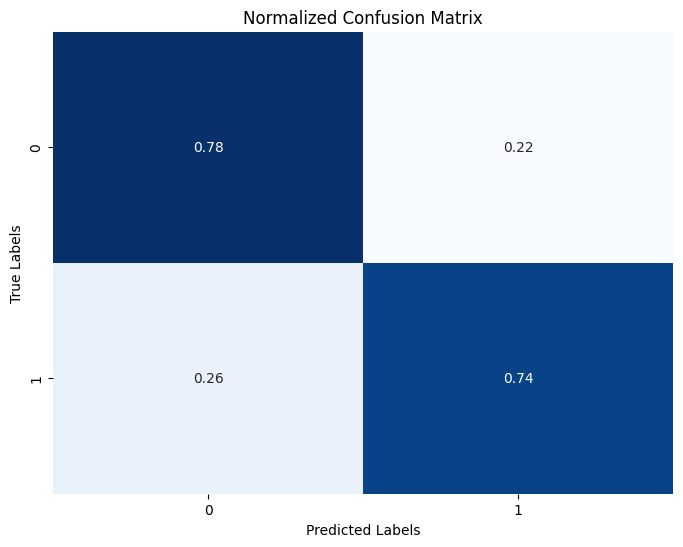

              precision    recall  f1-score   support

           0       0.92      0.78      0.85      2389
           1       0.47      0.74      0.57       611

    accuracy                           0.78      3000
   macro avg       0.70      0.76      0.71      3000
weighted avg       0.83      0.78      0.79      3000



array([1, 0, 0, ..., 1, 0, 0])

In [15]:
predictions = grid.predict(X_test)

cm = confusion_matrix(y_test, predictions)
print(cm)

cm_normalized = np.around(cm / cm.sum(axis=1)[:, np.newaxis], 2)
print(cm_normalized)

import seaborn as sns
import matplotlib.pyplot as plt

# Assuming cm and cm_normalized are already defined

# Visualizing the Confusion Matrix
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()

plt.figure(figsize=(8, 6))
sns.heatmap(cm_normalized, annot=True, cmap='Blues', cbar=False)
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Normalized Confusion Matrix')
plt.show()


print(classification_report(y_test, predictions))


predictions

In [16]:
pred = grid.predict(X_test[:1])
print(f"Predicted classes: {pred}")
print(f"Actual Labels: {list(y_test[:1])}")

Predicted classes: [1]
Actual Labels: [1]
